In [1]:
library(ggplot2)
library(ggbreak)
library(glue)
library(yaml)
library(ggforce)
library(dplyr)
library(stringr)
library(purrr)
library(tidyr)
library(glue)
library(RColorBrewer)
library(stats)
library(dendextend)
library(gplots)
library(jsonlite)
library(patchwork)
library(heatmaply)
library(pals)
library(ellipse)
library(plotly)
library(htmlwidgets)
library(webshot2)
library(ComplexHeatmap)
library(circlize)
library(rstatix)


ggbreak v0.1.6 Learn more at https://yulab-smu.top/



If you use ggbreak in published research, please cite the following
paper:

S Xu, M Chen, T Feng, L Zhan, L Zhou, G Yu. Use ggbreak to effectively
utilize plotting space to deal with large datasets and outliers.
Frontiers in Genetics. 2021, 12:774846. doi: 10.3389/fgene.2021.774846



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



---------------------
Welcome to dendextend version 1.19.1
Type citation('dendextend') for how to cite the package.

Type browseVignettes(package = 'dendextend') for the package vignette.
The github page is: https://github.com/talgalili/dendextend/

Suggestions and bug-reports can be submitted at: https://github.com/talgalili/dendextend/issues
You may ask questions at stackoverflow, use the r and dendextend tags: 
	 https://stackoverflow.com/questions/ta

In [2]:
sequences_group <- 'bacteria_1'
path <- "../../Results/RDPG"
hyperparameter <- 'euclidean_KNN_k-25_d-0'
preferred_order <- c("TNF & DNABERT-S", "dna2vec & DNABERT-S", "HyenaDNA & DNABERT-S", "DNABERT-S & DNABERT-2", "TNF & DNABERT-2", "DNABERT-2 & dna2vec","HyenaDNA & DNABERT-2",  "TNF & HyenaDNA", "dna2vec & HyenaDNA", "dna2vec & TNF")

evidence_per_seq_min = read.table(glue("{path}/{sequences_group}_evidence_pvalues_{hyperparameter}.tsv"), header = T, sep='\t')
rownames(evidence_per_seq_min) <- paste("seq-", 1:nrow(evidence_per_seq_min), sep = "")


In [4]:
distance_matrix_min_seq = dist(evidence_per_seq_min)
h_min_seq = hclust(distance_matrix_min_seq, method = "ward.D2")
clusters_evidence <- cutree(h_min_seq, k = 9)

In [5]:
cluster_color_map <- setNames(
  c('#ff97d7', "#ffde59", "#7800ff", "#ff8b44", '#75edf2', "#9abc1d", "#2300ff", '#aea1ad', "#94002a"),
  1:9
)

my_palette_evidence <- rev(colorRampPalette(brewer.pal(9, "RdBu"))(200))
breaks_seq_evidence <- seq(min(evidence_per_seq_min), max(evidence_per_seq_min), length.out = 201)

In [6]:
name_map_evidence <- c(
  "dna2vec_tnf_e" = "dna2vec & TNF",
  "tnf_dna2vec_e" = "dna2vec & TNF",

  "tnf_dnabert2_e" = "TNF & DNABERT-2",
  "dnabert2_tnf_e" = "TNF & DNABERT-2",

  "dnabert2_dna2vec_e" = "DNABERT-2 & dna2vec",
  "dna2vec_dnabert2_e" = "DNABERT-2 & dna2vec",

  "tnf_dnaberts_e" = "TNF & DNABERT-S",
  "dnaberts_tnf_e" = "TNF & DNABERT-S",

  "dna2vec_dnaberts_e" = "dna2vec & DNABERT-S",
  "dnaberts_dna2vec_e" = "dna2vec & DNABERT-S",

  "dnaberts_dnabert2_e" = "DNABERT-S & DNABERT-2",
  "dnabert2_dnaberts_e" = "DNABERT-S & DNABERT-2",

  "tnf_hyenadna_e" = "TNF & HyenaDNA",
  "hyenadna_tnf_e" = "TNF & HyenaDNA",

  "dna2vec_hyenadna_e" = "dna2vec & HyenaDNA",
  "hyenadna_dna2vec_e" = "dna2vec & HyenaDNA",

  "hyenadna_dnabert2_e" = "HyenaDNA & DNABERT-2",
  "dnabert2_hyenadna_e" = "HyenaDNA & DNABERT-2",

  "hyenadna_dnaberts_e" = "HyenaDNA & DNABERT-S",
  "dnaberts_hyenadna_e" = "HyenaDNA & DNABERT-S"
)

In [7]:
colnames(evidence_per_seq_min) <- name_map_evidence[colnames(evidence_per_seq_min)]
mat_evidence <- as.matrix(evidence_per_seq_min)[, preferred_order]

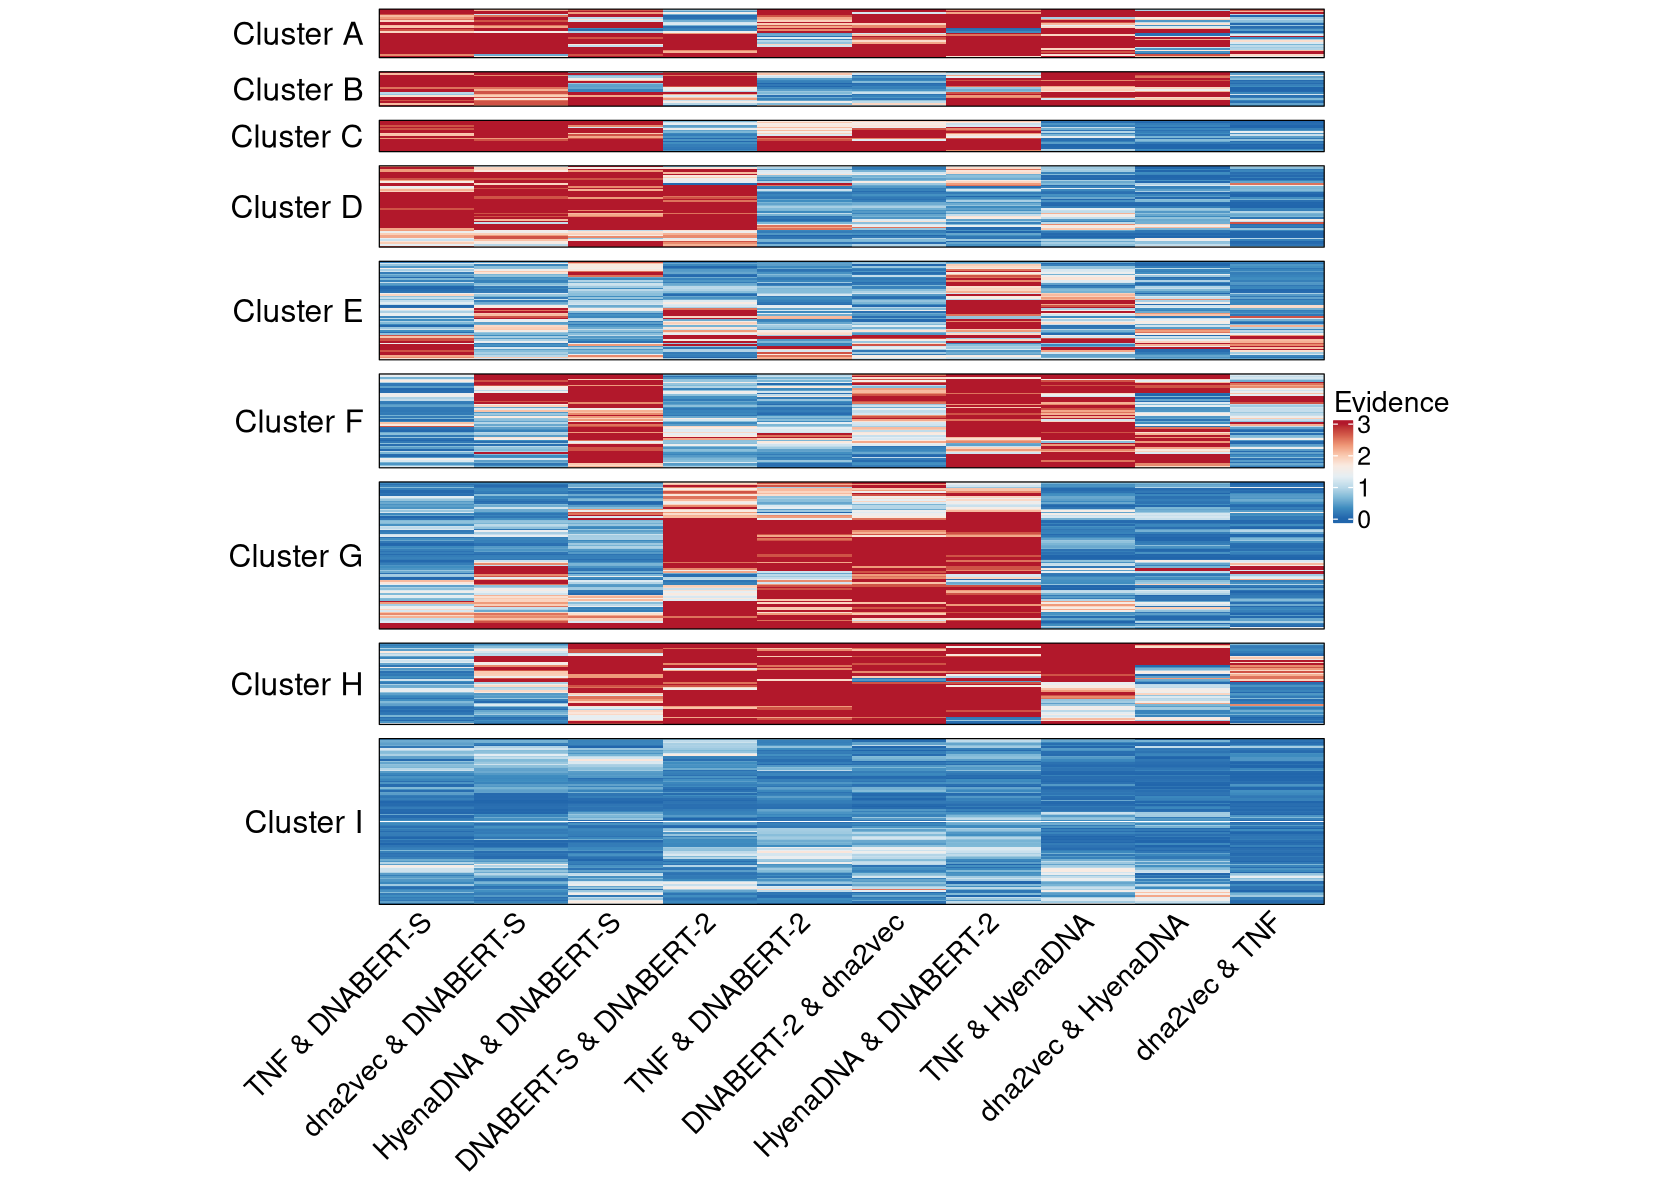

In [10]:
options(repr.plot.width = 14, repr.plot.height = 10)

ht_main <- Heatmap(
  mat_evidence,
  name = "Evidence",
  cluster_rows = rev(h_min_seq),
  cluster_columns = FALSE,
  show_row_names = FALSE,
  col = colorRamp2(
    breaks_seq_evidence[seq(1, 201, length.out = 10)],
    my_palette_evidence[seq(1, 200, length.out = 10)]
  ),
  row_split = 9,
  row_gap = unit(3, "mm"),
  border = TRUE,
  column_names_rot = 45,
  column_names_gp = gpar(fontsize = 17),
  width = unit(20, "cm"),
  show_row_dend = FALSE,
  row_title = paste("Cluster", LETTERS[1:9]),
  row_title_rot = 0,
  row_title_side = "left",
  row_title_gp = gpar(fontsize = 19),
  heatmap_legend_param = list(
    title_gp = gpar(fontsize = 17),
    labels_gp = gpar(fontsize = 15)
  )
)
ht_main

In [9]:
sequences_annotations <- read.table(glue("{path}/sequences_annot_with_entropy.csv"), header = T, sep=',')
colnames(sequences_annotations)[colnames(sequences_annotations) == 'seq_id'] <- 'seq_id_first'
sequences_annotations$seq_id <- paste("seq-", 1:nrow(sequences_annotations), sep = "")
colnames(sequences_annotations)[colnames(sequences_annotations) == 'nb_orfs'] <- 'ORF'
colnames(sequences_annotations)[colnames(sequences_annotations) == 'per.GC'] <- 'GC %'
colnames(sequences_annotations)[colnames(sequences_annotations) == 'coding_pct'] <- 'CDS %'
colnames(sequences_annotations)[colnames(sequences_annotations) == 'coding_pct_plus'] <- 'C+/n %'
colnames(sequences_annotations)[colnames(sequences_annotations) == 'coding_pct_minus'] <- 'C-/n %'
colnames(sequences_annotations)[colnames(sequences_annotations) == 'pct_plus_in_coding_pct'] <- 'C+/C %'
colnames(sequences_annotations)[colnames(sequences_annotations) == 'Shannon.Entropy'] <- 'Ent.'

Warning message in file(file, "rt"):
“cannot open file '../../Results/RDPG/sequences_annot_with_entropy.csv': No such file or directory”


ERROR: Error in file(file, "rt"): cannot open the connection
